# Data Preparation

*Detecting Modern LLM-Generated Fake News: A Cross-Generator Robustness Study*

**What this notebook does:** loads your 3 clean CSVs → audits them → removes duplicates/overlap → scrubs source "giveaway" tokens → EDA figures → saves
`outputs/data/splits.pkl` for the next notebooks.

Labels: `1 = real`, `0 = fake` (fake = positive class in all metrics).
**Next:** `2_Train_Models.ipynb`

In [8]:
DATA_DIR = "C:\\Users\\megha\\Downloads\\FND_project\\files"        # folder that contains train_clean.csv, evaluation_clean.csv, test_clean.csv
OUT_DIR = r"C:\Users\megha\OneDrive\Documents\fake_news_app\outputs"
SEED     = 42

In [9]:
import os, re, glob, time, json, warnings, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
import joblib
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED)

OUT = Path(OUT_DIR)
for sub in ["figures", "tables", "models", "data", "generated"]: (OUT / sub).mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.25, palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

def savefig(name):
    plt.savefig(OUT / "figures" / f"{name}.png"); plt.savefig(OUT / "figures" / f"{name}.pdf"); plt.show()

def save_table(df, name, index=True):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index)
    try: (OUT / "tables" / f"{name}.tex").write_text(df.to_latex(index=index, float_format="%.4f"))
    except Exception: pass
    return df
print("Setup OK")

Setup OK


### 1.1 Load the three splits

In [10]:
def find_split(kind):
    """Finds the correct '<kind>_clean.csv' (must contain title,text,label,word_count) even if other copies exist."""
    for f in sorted(glob.glob(os.path.join(DATA_DIR, f"*{kind}_clean*.csv"))):
        cols = pd.read_csv(f, nrows=0).columns
        if {"title", "text", "label", "word_count"}.issubset(cols): return f
    raise FileNotFoundError(f"No '{kind}_clean.csv' with columns title,text,label,word_count in {DATA_DIR}")

def load(kind):
    f = find_split(kind)
    d = pd.read_csv(f, usecols=["title", "text", "label"]).dropna(subset=["title", "text", "label"])
    d["label"] = pd.to_numeric(d["label"], errors="coerce"); d = d.dropna(subset=["label"]); d["label"] = d["label"].astype(int)
    d = d[d.label.isin([0, 1])].reset_index(drop=True)
    d["doc"] = d["title"].str.strip() + ". " + d["text"].str.strip()
    print(f"{kind:11s} <- {os.path.basename(f)}  rows={len(d):,}")
    return d
train, val, test = load("train"), load("evaluation"), load("test")

train       <- train_clean.csv  rows=24,177
evaluation  <- evaluation_clean.csv  rows=8,048
test        <- test_clean.csv  rows=8,060


### 1.2 Audit: duplicates and train/val/test overlap (data leakage)

In [11]:
key = lambda d: d["doc"].str.lower().str.replace(r"\s+", " ", regex=True).str[:300]
ks = {"train": set(key(train)), "val": set(key(val)), "test": set(key(test))}
print("Overlaps before cleaning:", {"train∩val": len(ks["train"] & ks["val"]), "train∩test": len(ks["train"] & ks["test"]), "val∩test": len(ks["val"] & ks["test"])})
train = train.drop_duplicates("doc").reset_index(drop=True)
val  = val[~key(val).isin(ks["train"])].drop_duplicates("doc").reset_index(drop=True)
test = test[~key(test).isin(ks["train"] | ks["val"])].drop_duplicates("doc").reset_index(drop=True)
splits = {"train": train, "val": val, "test": test}
summary = pd.DataFrame({k: {"articles": len(d), "real (1)": int((d.label == 1).sum()), "fake (0)": int((d.label == 0).sum()),
                            "fake %": round(100 * (d.label == 0).mean(), 1)} for k, d in splits.items()}).T
save_table(summary, "t1_dataset_summary"); display(summary)
for l, n in [(1, "REAL"), (0, "FAKE")]: print(f"\n{n} sample titles:"); print(*train[train.label == l].title.head(3).tolist(), sep="\n  - ")

Overlaps before cleaning: {'train∩val': 26, 'train∩test': 28, 'val∩test': 10}


,articles,real (1),fake (0),fake %
train,24177.0,13231.0,10946.0,45.3
val,8022.0,4286.0,3736.0,46.6
test,8023.0,4325.0,3698.0,46.1



REAL sample titles:
Palestinians switch off Christmas lights in Bethlehem in anti-Trump protest
  - China says Trump call with Taiwan president won't change island's status
  - Zimbabwe military chief's China trip was normal visit, Beijing says

FAKE sample titles:
FAIL! The Trump Organization’s Credit Score Will Make You Laugh
  - THE MOST UNCOURAGEOUS PRESIDENT EVER Receives A Courage Award…Proceeds To Whine About Current President
  - WATCH: John Oliver Presents GOP Debates As ‘Clowntown F*ck-the-World Sh*tshow 2016’


### 1.3 Source-leakage check and scrubbing

Fake and real articles come from different websites, so tokens such as *via*, *Getty Images*, *VIDEO* reveal the **source**, not the truthfulness. We remove them so the detectors learn real content/style.

In [12]:
markers = {"'Reuters'": r"reuters", "'via'": r"\bvia\b", "'Getty'": r"getty", "'featured image'": r"featured image|image via",
           "'VIDEO/WATCH'": r"\b(video|watch)\b", "'read more'": r"read more", "'21st Century Wire'": r"21st century wire",
           "'@' handles": r"@\w+", "http link": r"https?://"}
leak = pd.DataFrame({n: {"real %": 100 * train[train.label == 1].doc.str.contains(p, case=False, regex=True).mean(),
                         "fake %": 100 * train[train.label == 0].doc.str.contains(p, case=False, regex=True).mean()} for n, p in markers.items()}).T.round(2)
save_table(leak, "t2_leakage_markers"); display(leak)

LEAK_PATTERNS = [r"\(?reuters\)?", r"\bvia\b", r"getty images?", r"featured image", r"image via", r"\bimage\b",
                 r"\b(video|watch|breaking)\b", r"read more", r"21st century wire", r"@\w+", r"https?://\S+", r"\bpic\.twitter\.com\S*",
                 r"\(\s*(update|details|images?|video)\s*\)"]
(OUT / "data" / "scrub_patterns.json").write_text(json.dumps(LEAK_PATTERNS))
LEAK_RE = re.compile("|".join(LEAK_PATTERNS), flags=re.I)
def scrub(s): return re.sub(r"\s+", " ", LEAK_RE.sub(" ", s)).strip()
for d in splits.values(): d["doc_raw"] = d["doc"]; d["doc"] = d["doc_raw"].map(scrub); d["n_words"] = d["doc"].str.split().str.len()
print("Example after scrubbing:\n", train.doc.iloc[0][:300])

,real %,fake %
'Reuters',22.61,1.26
'via',2.44,53.06
'Getty',0.11,21.65
'featured image',0.07,45.23
'VIDEO/WATCH',5.51,47.82
'read more',0.18,9.58
'21st Century Wire',0.00,3.28
'@' handles,1.31,25.24
http link,0.00,13.25


Example after scrubbing:
 Palestinians switch off Christmas lights in Bethlehem in anti-Trump protest. Palestinians switched off Christmas lights at Jesus traditional birthplace in Bethlehem on Wednesday night in protest at U.S. President Donald Trump s decision to recognize Jerusalem as Israel s capital. A Christmas tree ad


### 1.4 EDA figure (Figure 1 for the paper)

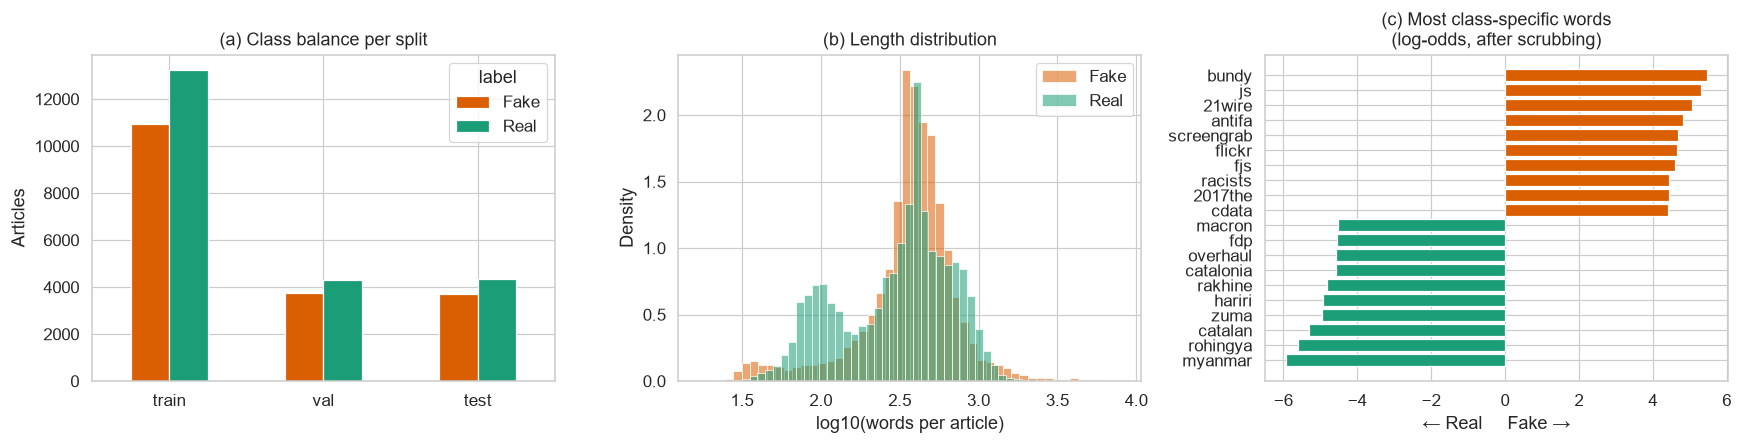

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
fake,10946.0,450.1,379.1,17.0,292.0,391.0,522.0,7929.0
real,13231.0,400.8,311.3,20.0,158.0,366.0,537.0,5834.0


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cnt = pd.DataFrame({k: d.label.map({0: "Fake", 1: "Real"}).value_counts() for k, d in splits.items()}).T[["Fake", "Real"]]
cnt.plot(kind="bar", ax=ax[0], rot=0, color=["#d95f02", "#1b9e77"]); ax[0].set_title("(a) Class balance per split"); ax[0].set_ylabel("Articles")
for l, n, c in [(0, "Fake", "#d95f02"), (1, "Real", "#1b9e77")]:
    sns.histplot(np.log10(train[train.label == l].n_words.clip(lower=1)), bins=50, ax=ax[1], label=n, color=c, alpha=.55, stat="density")
ax[1].set_xlabel("log10(words per article)"); ax[1].set_title("(b) Length distribution"); ax[1].legend()
sub = train.sample(6000, random_state=SEED)
cv = CountVectorizer(stop_words="english", max_features=20000, min_df=5); C = cv.fit_transform(sub.doc); voc = np.array(cv.get_feature_names_out())
fr = np.asarray(C[(sub.label == 0).values].sum(0)).ravel(); rr = np.asarray(C[(sub.label == 1).values].sum(0)).ravel()
lo = np.log((fr + 1) / fr.sum()) - np.log((rr + 1) / rr.sum()); idx = np.r_[np.argsort(lo)[:10], np.argsort(lo)[-10:]]
ax[2].barh(voc[idx], lo[idx], color=["#1b9e77"] * 10 + ["#d95f02"] * 10); ax[2].set_title("(c) Most class-specific words\n(log-odds, after scrubbing)"); ax[2].set_xlabel("← Real     Fake →")
plt.tight_layout(); savefig("fig1_eda")
display(train.groupby("label").n_words.describe().round(1).rename(index={0: "fake", 1: "real"}))

### 1.5 Save for the next notebooks

In [14]:
joblib.dump(splits, OUT / "data" / "splits.pkl")
print({k: len(v) for k, v in splits.items()}, "-> saved to", OUT / "data" / "splits.pkl")
print("✅ Notebook 1 finished. Now open 2_Train_Models.ipynb")

{'train': 24177, 'val': 8022, 'test': 8023} -> saved to C:\Users\megha\OneDrive\Documents\fake_news_app\outputs\data\splits.pkl
✅ Notebook 1 finished. Now open 2_Train_Models.ipynb
